# House Price Prediction
---------
### Problem Statement

Task 1:- Prepare a complete data analysis report on the given data.

Task 2:-a) Create a robust machine learning algorithm to accurately predict the price of the house given the various factors across the market.
b) Determine the relationship between the house features and how the price varies based on this.

Task3:- Come up with suggestions for the customer to buy the house according to the area, price and other requirements.

###  Import Required Libraries

In [1]:
# Data Manipulation
import pandas as pd
import numpy as np

# Data Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Machine Learning
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

# Evaluation Metrics
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

#Models
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.ensemble import GradientBoostingRegressor

These libraries help in:
Data loading
Data cleaning
Visualization
Model building
Model evaluation

## Step 2: Load Dataset

In [2]:
df = pd.read_csv(r"C:\Users\BABLU BHAI\Downloads\CAPSTONE PROJECTS\PRCP-1020-HousePricePred\Data\data.csv")

### Basic data checks

In [3]:
df.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [4]:
df.shape

(1460, 81)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   object 
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   object 
 6   Alley          91 non-null     object 
 7   LotShape       1460 non-null   object 
 8   LandContour    1460 non-null   object 
 9   Utilities      1460 non-null   object 
 10  LotConfig      1460 non-null   object 
 11  LandSlope      1460 non-null   object 
 12  Neighborhood   1460 non-null   object 
 13  Condition1     1460 non-null   object 
 14  Condition2     1460 non-null   object 
 15  BldgType       1460 non-null   object 
 16  HouseStyle     1460 non-null   object 
 17  OverallQual    1460 non-null   int64  
 18  OverallC

In [6]:
df.describe()

,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
count,1460.000000,1460.000000,1201.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1452.000000,1460.000000,...,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000
mean,730.500000,56.897260,70.049958,10516.828082,6.099315,5.575342,1971.267808,1984.865753,103.685262,443.639726,...,94.244521,46.660274,21.954110,3.409589,15.060959,2.758904,43.489041,6.321918,2007.815753,180921.195890
std,421.610009,42.300571,24.284752,9981.264932,1.382997,1.112799,30.202904,20.645407,181.066207,456.098091,...,125.338794,66.256028,61.119149,29.317331,55.757415,40.177307,496.123024,2.703626,1.328095,79442.502883
min,1.000000,20.000000,21.000000,1300.000000,1.000000,1.000000,1872.000000,1950.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2006.000000,34900.000000
25%,365.750000,20.000000,59.000000,7553.500000,5.000000,5.000000,1954.000000,1967.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,2007.000000,129975.000000
50%,730.500000,50.000000,69.000000,9478.500000,6.000000,5.000000,1973.000000,1994.000000,0.000000,383.500000,...,0.000000,25.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,2008.000000,163000.000000
75%,1095.250000,70.000000,80.000000,11601.500000,7.000000,6.000000,2000.000000,2004.000000,166.000000,712.250000,...,168.000000,68.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.000000,2009.000000,214000.000000
max,1460.000000,190.000000,313.000000,215245.000000,10.000000,9.000000,2010.000000,2010.000000,1600.000000,5644.000000,...,857.000000,547.000000,552.000000,508.000000,480.000000,738.000000,15500.000000,12.000000,2010.000000,755000.000000


## Basic Data Analysis

#### Total Missing Values

In [7]:
df.isnull().sum()

Id                 0
MSSubClass         0
MSZoning           0
LotFrontage      259
LotArea            0
                ... 
MoSold             0
YrSold             0
SaleType           0
SaleCondition      0
SalePrice          0
Length: 81, dtype: int64

#### Duplicate Records

In [8]:
df.duplicated().sum()

0

### Numerical and Categorical Features
The features are separated into numerical and categorical columns for further analysis.

In [9]:
# Numerical columns
num_cols = df.select_dtypes(include=['int64', 'float64']).columns

print("Number of Numerical Features :", len(num_cols))

num_cols

Number of Numerical Features : 38


Index(['Id', 'MSSubClass', 'LotFrontage', 'LotArea', 'OverallQual',
       'OverallCond', 'YearBuilt', 'YearRemodAdd', 'MasVnrArea', 'BsmtFinSF1',
       'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', '1stFlrSF', '2ndFlrSF',
       'LowQualFinSF', 'GrLivArea', 'BsmtFullBath', 'BsmtHalfBath', 'FullBath',
       'HalfBath', 'BedroomAbvGr', 'KitchenAbvGr', 'TotRmsAbvGrd',
       'Fireplaces', 'GarageYrBlt', 'GarageCars', 'GarageArea', 'WoodDeckSF',
       'OpenPorchSF', 'EnclosedPorch', '3SsnPorch', 'ScreenPorch', 'PoolArea',
       'MiscVal', 'MoSold', 'YrSold', 'SalePrice'],
      dtype='object')

In [10]:
# Categorical columns
cat_cols = df.select_dtypes(include=['object']).columns

print("Number of Categorical Features :", len(cat_cols))

cat_cols

Number of Categorical Features : 43


Index(['MSZoning', 'Street', 'Alley', 'LotShape', 'LandContour', 'Utilities',
       'LotConfig', 'LandSlope', 'Neighborhood', 'Condition1', 'Condition2',
       'BldgType', 'HouseStyle', 'RoofStyle', 'RoofMatl', 'Exterior1st',
       'Exterior2nd', 'MasVnrType', 'ExterQual', 'ExterCond', 'Foundation',
       'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2',
       'Heating', 'HeatingQC', 'CentralAir', 'Electrical', 'KitchenQual',
       'Functional', 'FireplaceQu', 'GarageType', 'GarageFinish', 'GarageQual',
       'GarageCond', 'PavedDrive', 'PoolQC', 'Fence', 'MiscFeature',
       'SaleType', 'SaleCondition'],
      dtype='object')

In [11]:
# Number of numerical and categorical features

print("Numerical Features :", len(num_cols))
print("Categorical Features :", len(cat_cols))
print("Total Features :", df.shape[1])

Numerical Features : 38
Categorical Features : 43
Total Features : 81


## Statistical Summary

In [12]:
df.describe()

,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
count,1460.000000,1460.000000,1201.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1452.000000,1460.000000,...,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000
mean,730.500000,56.897260,70.049958,10516.828082,6.099315,5.575342,1971.267808,1984.865753,103.685262,443.639726,...,94.244521,46.660274,21.954110,3.409589,15.060959,2.758904,43.489041,6.321918,2007.815753,180921.195890
std,421.610009,42.300571,24.284752,9981.264932,1.382997,1.112799,30.202904,20.645407,181.066207,456.098091,...,125.338794,66.256028,61.119149,29.317331,55.757415,40.177307,496.123024,2.703626,1.328095,79442.502883
min,1.000000,20.000000,21.000000,1300.000000,1.000000,1.000000,1872.000000,1950.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2006.000000,34900.000000
25%,365.750000,20.000000,59.000000,7553.500000,5.000000,5.000000,1954.000000,1967.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,2007.000000,129975.000000
50%,730.500000,50.000000,69.000000,9478.500000,6.000000,5.000000,1973.000000,1994.000000,0.000000,383.500000,...,0.000000,25.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,2008.000000,163000.000000
75%,1095.250000,70.000000,80.000000,11601.500000,7.000000,6.000000,2000.000000,2004.000000,166.000000,712.250000,...,168.000000,68.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.000000,2009.000000,214000.000000
max,1460.000000,190.000000,313.000000,215245.000000,10.000000,9.000000,2010.000000,2010.000000,1600.000000,5644.000000,...,857.000000,547.000000,552.000000,508.000000,480.000000,738.000000,15500.000000,12.000000,2010.000000,755000.000000


## Exploratory Data Analysis (EDA)

### SalePrice Distribution

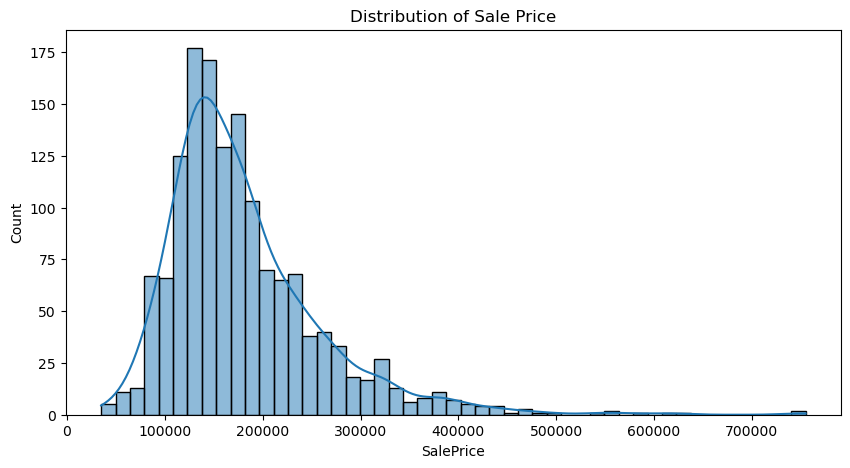

In [13]:
plt.figure(figsize=(10,5))
sns.histplot(df['SalePrice'], kde=True)
plt.title("Distribution of Sale Price")
plt.show()

#### Observation
- The SalePrice distribution is positively skewed.
- Most houses are sold in the lower to mid-price range.
- A few high-priced houses are present as outliers.

#### Distribution of Numerical Features

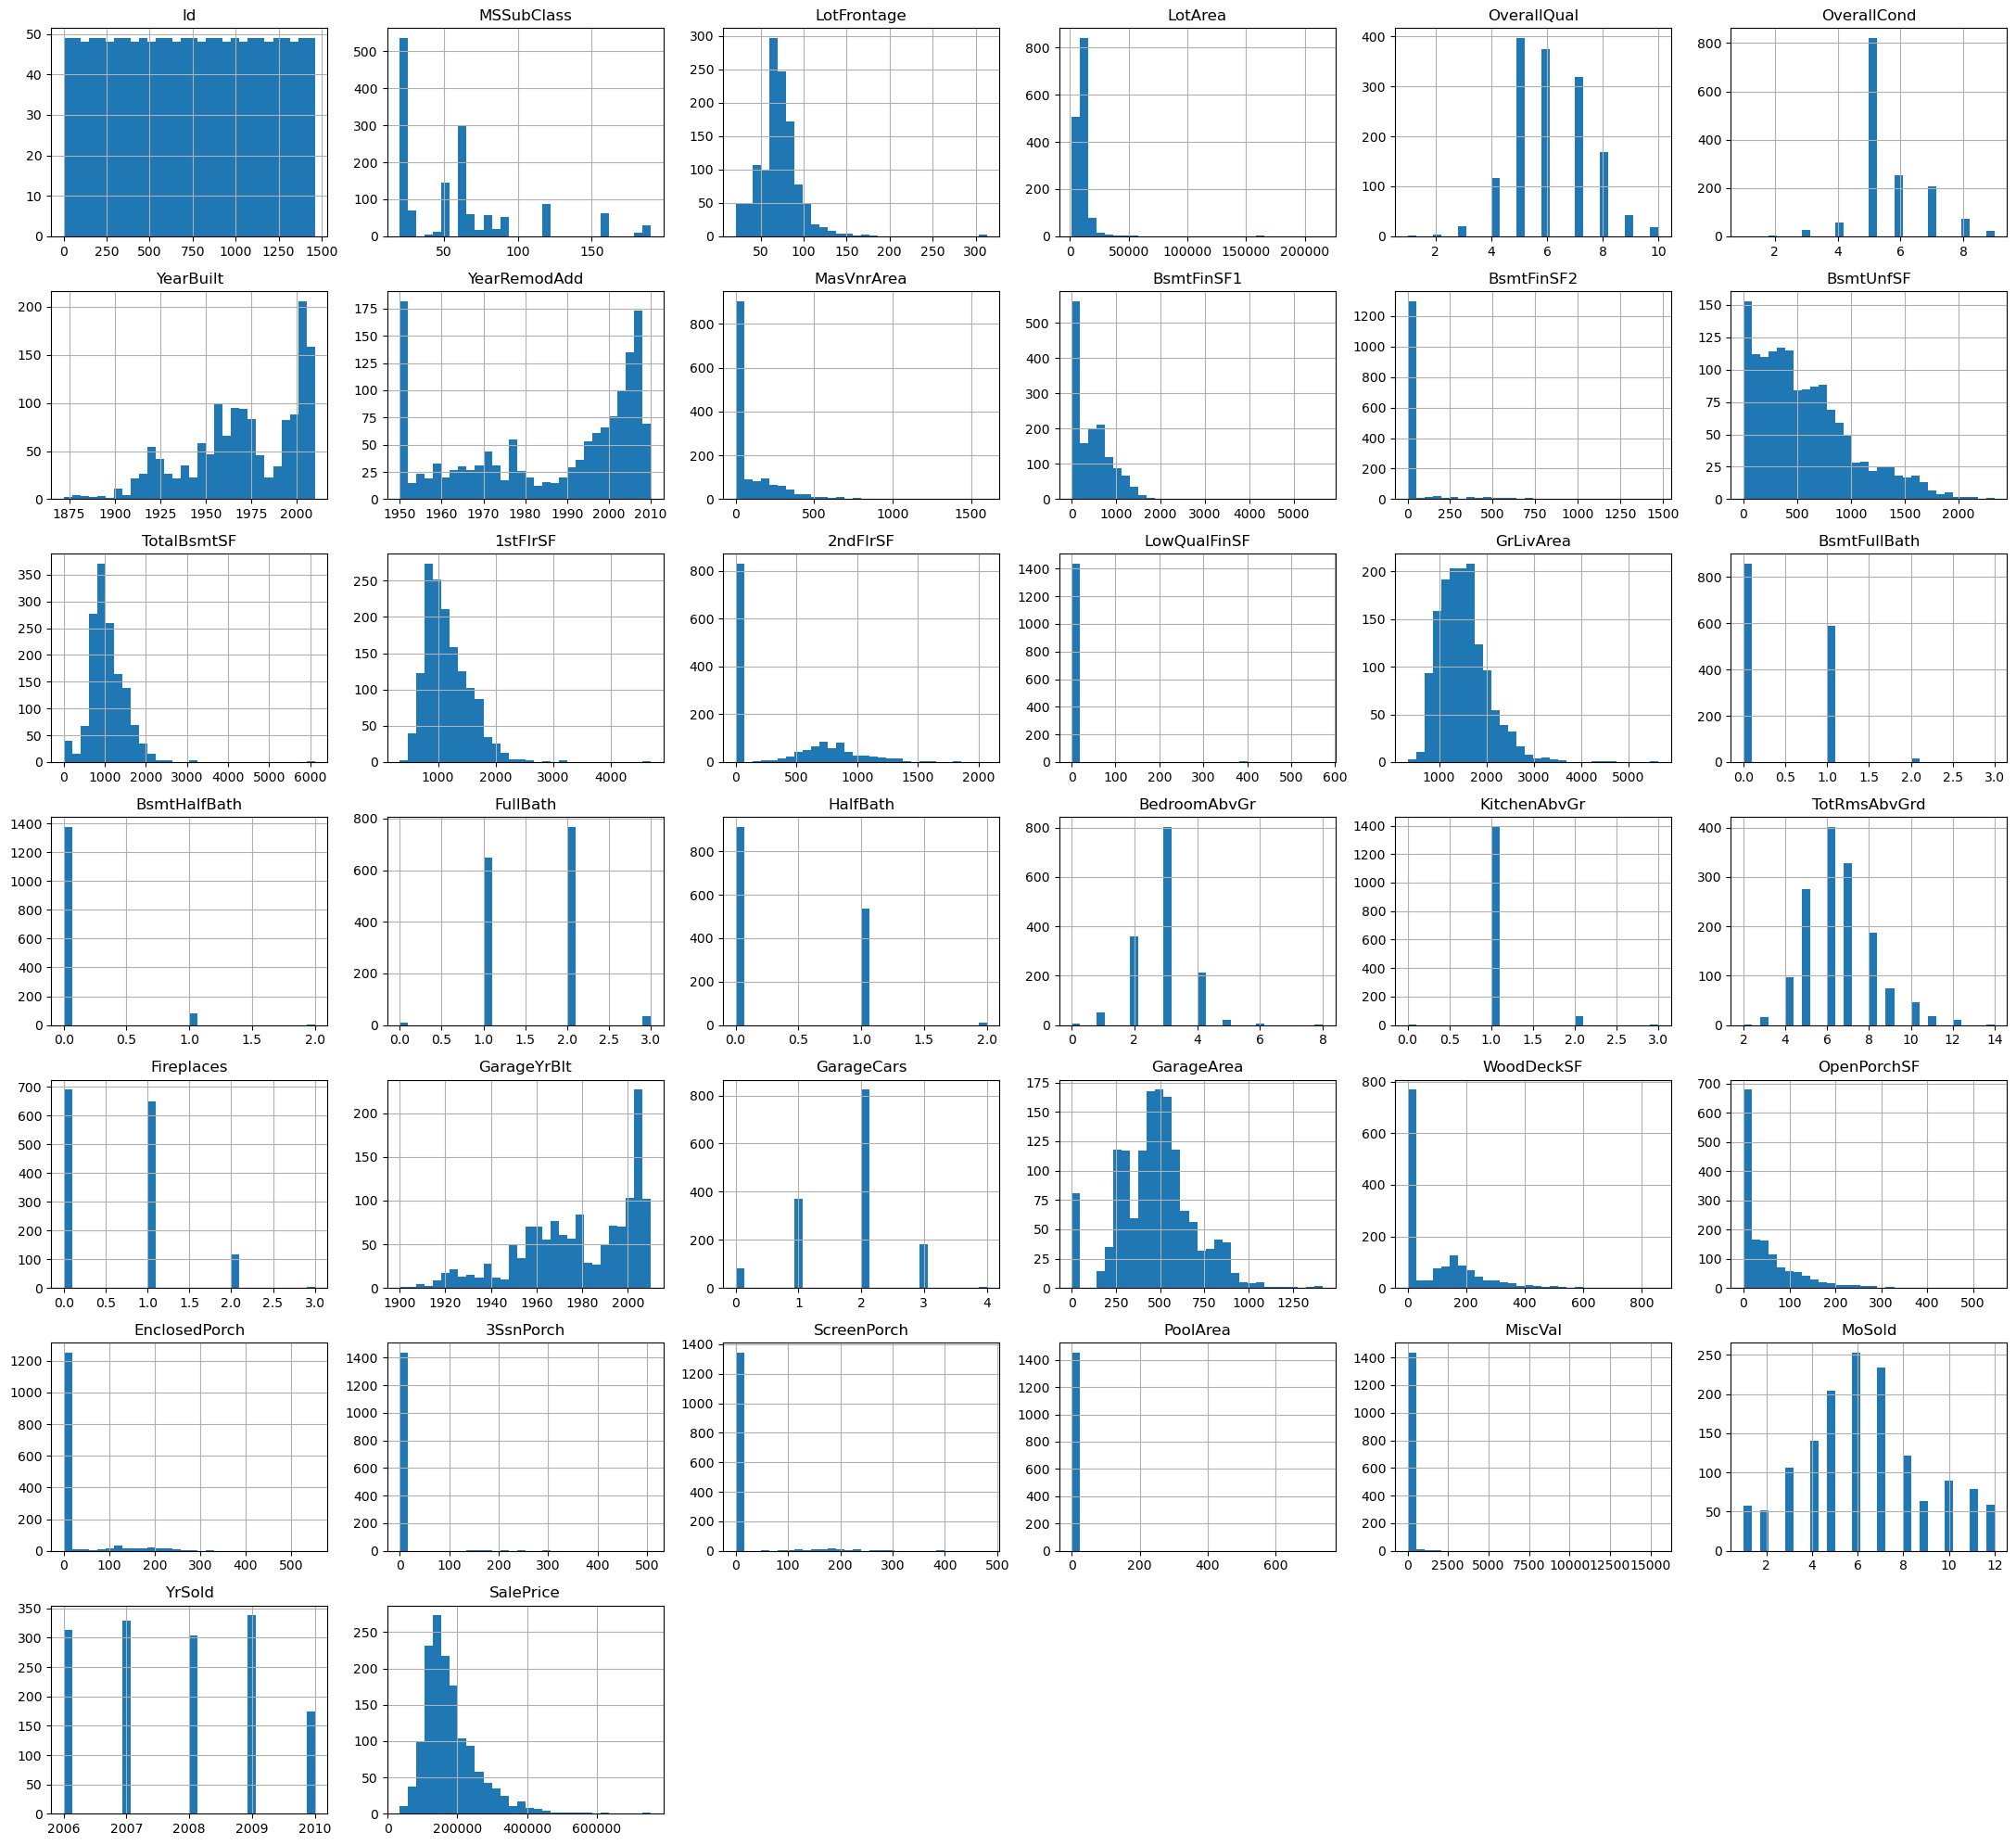

In [14]:
df[num_cols].hist(figsize=(22,20), bins=30)

plt.tight_layout()
plt.show()

### Observation
- Most numerical features have different distributions.
- Some features are normally distributed, while others are skewed.
- A few variables contain extreme values that may require further analysis.

### Correlation Heatmap

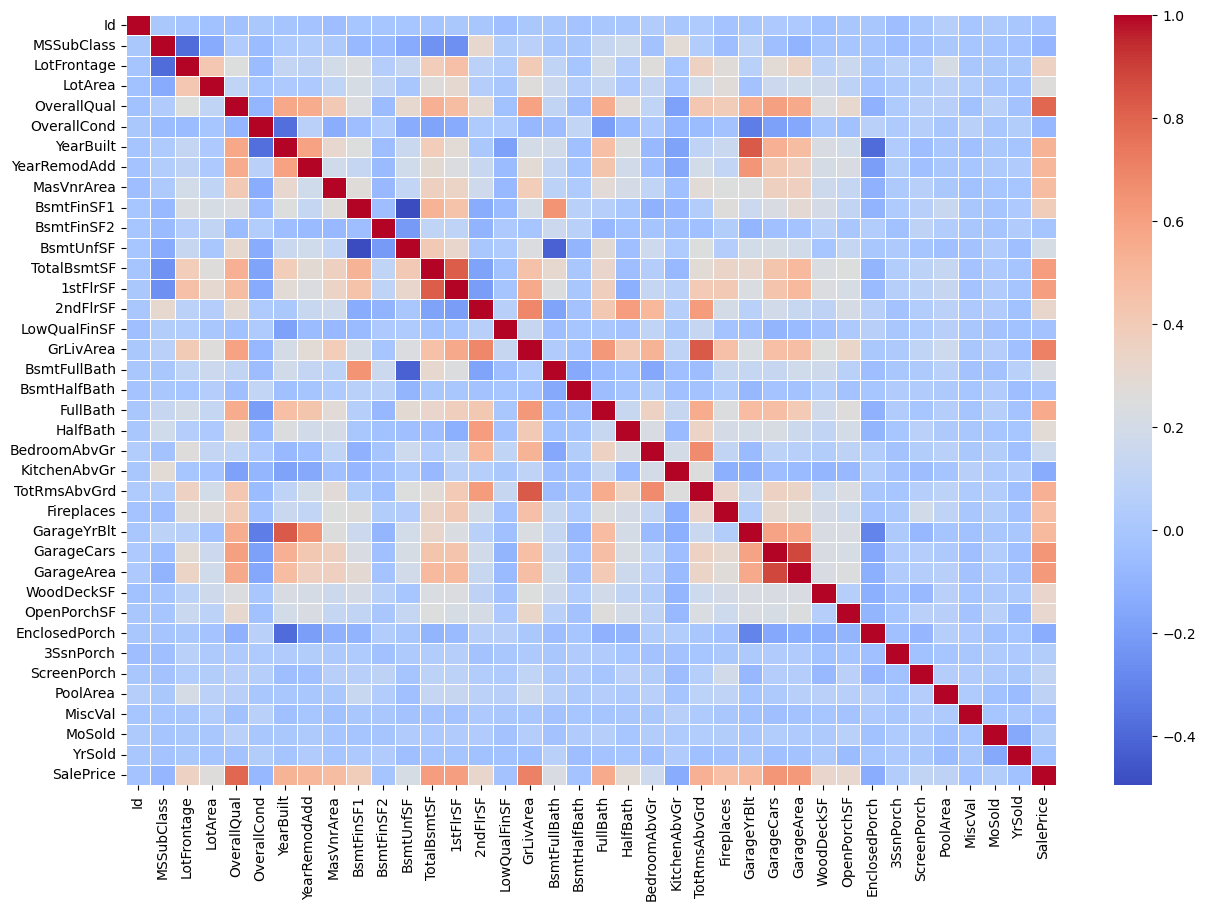

In [15]:
plt.figure(figsize=(15,10))

sns.heatmap(
    df.corr(numeric_only=True),
    cmap="coolwarm",
    linewidth=0.5
)

plt.show()


### Observation
- The heatmap shows the correlation between numerical features.
- Features with higher correlation to SalePrice are more useful for prediction.
- Highly correlated features can also help in feature selection.

### SalePrice Box Plot

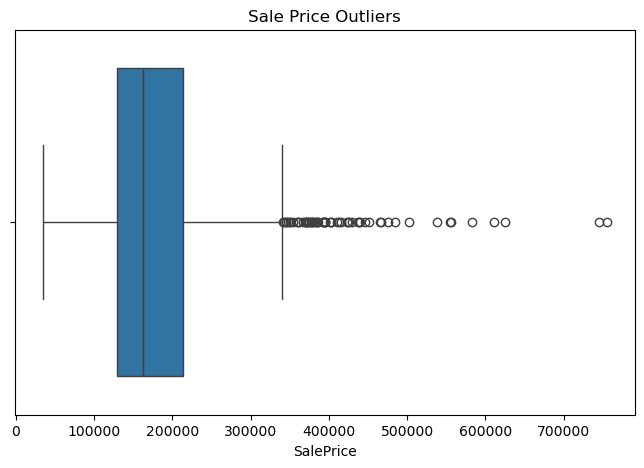

In [16]:
plt.figure(figsize=(8,5))
sns.boxplot(x=df['SalePrice'])
plt.title("Sale Price Outliers")
plt.show()

### Scatter Plot: Living Area vs Price

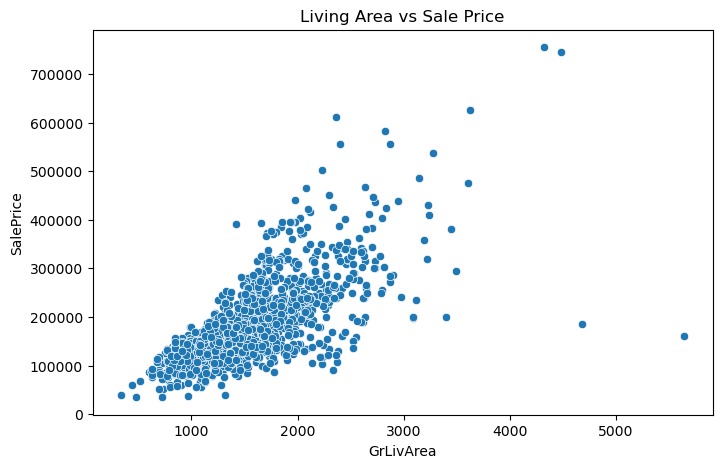

In [17]:
plt.figure(figsize=(8,5))
sns.scatterplot(x='GrLivArea', y='SalePrice', data=df)
plt.title("Living Area vs Sale Price")
plt.show()

### Scatter Plot: Quality vs Price

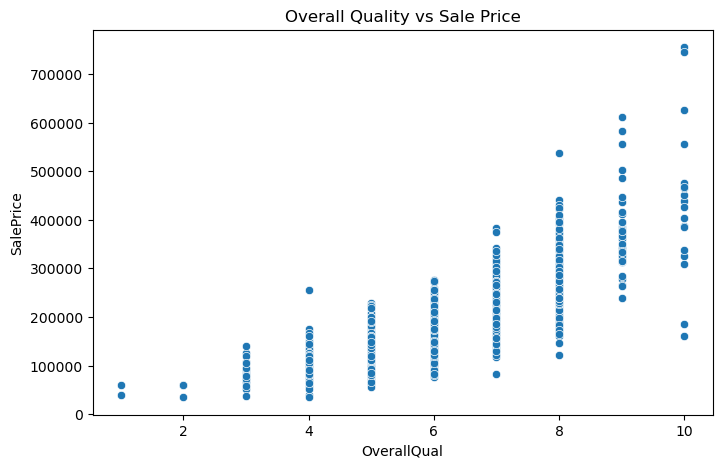

In [18]:
plt.figure(figsize=(8,5))
sns.scatterplot(x='OverallQual', y='SalePrice', data=df)
plt.title("Overall Quality vs Sale Price")
plt.show()

## Observation

* Shows relationships between features

### Top Features Correlated with SalePrice

In [19]:
corr = df.corr(numeric_only=True)['SalePrice']
corr.sort_values(ascending=False).head(15)

SalePrice       1.000000
OverallQual     0.790982
GrLivArea       0.708624
GarageCars      0.640409
GarageArea      0.623431
TotalBsmtSF     0.613581
1stFlrSF        0.605852
FullBath        0.560664
TotRmsAbvGrd    0.533723
YearBuilt       0.522897
YearRemodAdd    0.507101
GarageYrBlt     0.486362
MasVnrArea      0.477493
Fireplaces      0.466929
BsmtFinSF1      0.386420
Name: SalePrice, dtype: float64

## Expected important variables:

* OverallQual
* GrLivArea
* GarageCars
* GarageArea
* TotalBsmtSF
* FullBath
* YearBuilt

* These features generally have strong influence on house price.

## Data Cleaning

In [20]:
import warnings
warnings.filterwarnings('ignore')

In [21]:
num_cols = df.select_dtypes(include=np.number).columns

for col in num_cols:
    df[col].fillna(df[col].median(), inplace=True)

In [22]:
cat_cols = df.select_dtypes(include='object').columns

for col in cat_cols:
    df[col].fillna(df[col].mode()[0], inplace=True)

In [23]:
df.drop_duplicates(inplace=True)

above 3 cells are showing
MISSING VALUES

- For numerical columns
- For categorical columns
- Remove Duplicates

## Feature Engineering

In [24]:
df['HouseAge'] = df['YrSold'] - df['YearBuilt']

df['TotalBathrooms'] = (
    df['FullBath']
    + 0.5 * df['HalfBath']
    + df['BsmtFullBath']
    + 0.5 * df['BsmtHalfBath']
)

In [25]:
df['TotalSF'] = (
    df['TotalBsmtSF']
    + df['1stFlrSF']
    + df['2ndFlrSF']
)

* These new features often improve model accuracy.

## Encoding

In [26]:
from sklearn.preprocessing import LabelEncoder

In [27]:
cat_cols = df.select_dtypes(include='object').columns

print(cat_cols)

Index(['MSZoning', 'Street', 'Alley', 'LotShape', 'LandContour', 'Utilities',
       'LotConfig', 'LandSlope', 'Neighborhood', 'Condition1', 'Condition2',
       'BldgType', 'HouseStyle', 'RoofStyle', 'RoofMatl', 'Exterior1st',
       'Exterior2nd', 'MasVnrType', 'ExterQual', 'ExterCond', 'Foundation',
       'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2',
       'Heating', 'HeatingQC', 'CentralAir', 'Electrical', 'KitchenQual',
       'Functional', 'FireplaceQu', 'GarageType', 'GarageFinish', 'GarageQual',
       'GarageCond', 'PavedDrive', 'PoolQC', 'Fence', 'MiscFeature',
       'SaleType', 'SaleCondition'],
      dtype='object')


In [28]:
le = LabelEncoder()

for col in cat_cols:
    df[col] = le.fit_transform(df[col].astype(str))

In [29]:
df.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice,HouseAge,TotalSF
0,1,60,3,65.0,8450,1,0,3,3,0,...,2,2,0,2,2008,8,4,208500,5,2566
1,2,20,3,80.0,9600,1,0,3,3,0,...,2,2,0,5,2007,8,4,181500,31,2524
2,3,60,3,68.0,11250,1,0,0,3,0,...,2,2,0,9,2008,8,4,223500,7,2706
3,4,70,3,60.0,9550,1,0,0,3,0,...,2,2,0,2,2006,8,0,140000,91,2473
4,5,60,3,84.0,14260,1,0,0,3,0,...,2,2,0,12,2008,8,4,250000,8,3343


In [30]:
df = pd.get_dummies(
    df,
    drop_first=True
)

In [31]:
df.shape

(1460, 83)

In [32]:
df.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice,HouseAge,TotalSF
0,1,60,3,65.0,8450,1,0,3,3,0,...,2,2,0,2,2008,8,4,208500,5,2566
1,2,20,3,80.0,9600,1,0,3,3,0,...,2,2,0,5,2007,8,4,181500,31,2524
2,3,60,3,68.0,11250,1,0,0,3,0,...,2,2,0,9,2008,8,4,223500,7,2706
3,4,70,3,60.0,9550,1,0,0,3,0,...,2,2,0,2,2006,8,0,140000,91,2473
4,5,60,3,84.0,14260,1,0,0,3,0,...,2,2,0,12,2008,8,4,250000,8,3343


## Convert Categorical Variables

In [33]:
le = LabelEncoder()

for col in cat_cols:
    df[col] = le.fit_transform(df[col].astype(str))

## Define X and y

In [34]:
X = df.drop('SalePrice', axis=1)

In [35]:
y = df['SalePrice']

## Train-Test Split

In [36]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

# Build Multiple Models

## 1.Linear Regression

In [37]:
lr = LinearRegression()
lr.fit(X_train, y_train)

lr_pred = lr.predict(X_test)

## 2.Random Forest

In [38]:
rf = RandomForestRegressor(
    n_estimators=200,
    random_state=42
)

rf.fit(X_train, y_train)

rf_pred = rf.predict(X_test)

## 3.Gradient Boosting

In [39]:
gb = GradientBoostingRegressor(
    n_estimators=200,
    random_state=42
)

gb.fit(X_train, y_train)

gb_pred = gb.predict(X_test)

## Evaluate Models

In [40]:
def evaluate(y_test, pred):

    print("MAE :", mean_absolute_error(y_test, pred))

    print("RMSE :", np.sqrt(
        mean_squared_error(y_test, pred)
    ))

    print("R2 :", r2_score(y_test, pred))

In [41]:
evaluate(y_test, lr_pred)

MAE : 21375.922817900766
RMSE : 35245.135128790476
R2 : 0.8380486674630949


In [42]:
evaluate(y_test, rf_pred)

MAE : 17745.28505136986
RMSE : 29561.542191561843
R2 : 0.8860694117644361


In [43]:
evaluate(y_test, gb_pred)

MAE : 16408.917218743318
RMSE : 27728.890204504227
R2 : 0.8997576724633959


## Model Comparison Report

In [44]:
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score
import numpy as np

def evaluate_model(y_test, pred):

    mae = mean_absolute_error(y_test, pred)

    rmse = np.sqrt(
        mean_squared_error(y_test, pred)
    )

    r2 = r2_score(y_test, pred)

    return mae, rmse, r2

In [45]:
lr_mae, lr_rmse, lr_r2 = evaluate_model(
    y_test,
    lr_pred
)

In [46]:
rf_mae, rf_rmse, rf_r2 = evaluate_model(
    y_test,
    rf_pred
)

In [47]:
gb_mae, gb_rmse, gb_r2 = evaluate_model(
    y_test,
    gb_pred
)

In [48]:
comparison = pd.DataFrame({

    "Model":[
        "Linear Regression",
        "Random Forest",
        "Gradient Boosting"
    ],

    "MAE":[
        lr_mae,
        rf_mae,
        gb_mae
    ],

    "RMSE":[
        lr_rmse,
        rf_rmse,
        gb_rmse
    ],

    "R2 Score":[
        lr_r2,
        rf_r2,
        gb_r2
    ]
})

comparison

,Model,MAE,RMSE,R2 Score
0,Linear Regression,21375.922818,35245.135129,0.838049
1,Random Forest,17745.285051,29561.542192,0.886069
2,Gradient Boosting,16408.917219,27728.890205,0.899758


### Model Comparison Report

Three machine learning models were developed for house price prediction: Linear Regression, Random Forest Regressor, and Gradient Boosting Regressor.

The models were evaluated using MAE, RMSE, and R² Score.

Linear Regression served as a baseline model and achieved moderate prediction performance. Random Forest improved prediction accuracy by capturing nonlinear relationships among house features. Gradient Boosting achieved the highest R² score and the lowest MAE and RMSE values.

Based on the evaluation metrics, Gradient Boosting Regressor was selected as the best model because it provided the most accurate predictions and demonstrated superior generalization performance on the test dataset.

Therefore, Gradient Boosting Regressor is recommended for production deployment.


## Feature Importance Analysis
   * Using Random Forest:

In [49]:
feature_importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': rf.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

feature_importance.head(10)

,Feature,Importance
81,TotalSF,0.385185
17,OverallQual,0.370646
44,2ndFlrSF,0.025873
19,YearBuilt,0.014694
80,HouseAge,0.012963
46,GrLivArea,0.011881
4,LotArea,0.011591
61,GarageCars,0.011590
3,LotFrontage,0.011552
34,BsmtFinSF1,0.010721


### Bar Chart

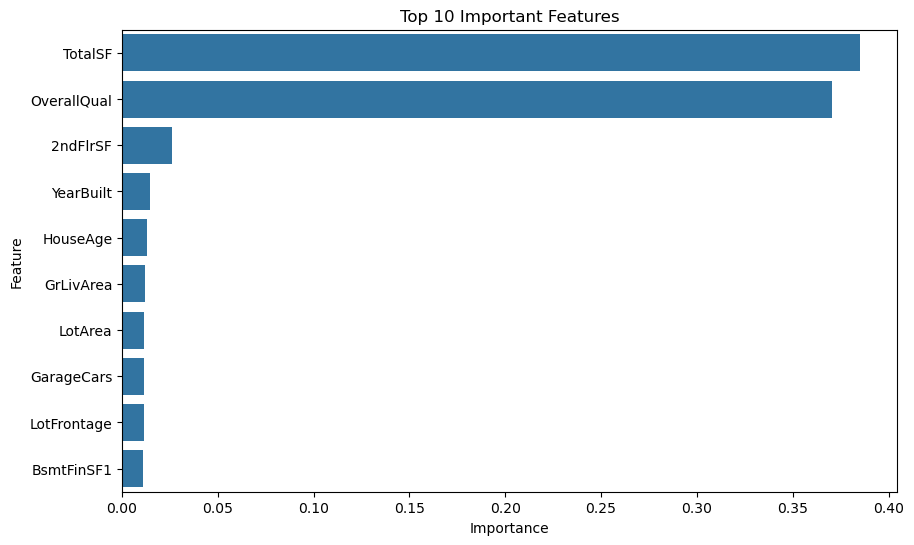

In [50]:
plt.figure(figsize=(10,6))
sns.barplot(
    x='Importance',
    y='Feature',
    data=feature_importance.head(10)
)
plt.title('Top 10 Important Features')
plt.show()

## Observation 
* OverallQual strongly affects house price.
* GrLivArea has a significant positive impact.
* GarageCars and GarageArea influence price.
* TotalBsmtSF contributes to higher house values.

## Customer Recommendation Report

#### Budget Buyer Recommended:

* Smaller lot area
* Older houses
* Fewer bedrooms
* Standard neighborhoods

#### Family Buyer Recommended:

* 3–4 bedrooms
* 2 bathrooms
* Large living area
* Good neighborhood

#### Luxury Buyer Recommended:

* High OverallQual
* Large GrLivArea
* Large GarageArea
* Premium neighborhoods

## Challenges Faced Report

##### Challenge 1: Missing Values
- Problem: Columns like PoolQC, Fence, Alley, and Garage attributes have a high number of missing values.
- Solution: Filled numerical columns using the Median and categorical columns using the Mode.
 
##### Challenge 2: Large Number of Categorical Features
- Problem: Several columns contain categorical (text) values.
- Solution: Converted categorical features using Label Encoding and One-Hot Encoding.
 
##### Challenge 3: Outliers
- Problem: The SalePrice column includes some extremely expensive houses.
- Solution: Detected outliers with the help of Box Plots and Histograms.
 
##### Challenge 4: High Dimensional Dataset
- Problem: The dataset contains a total of 81 columns.
- Solution: Performed Correlation Analysis and Feature Importance to identify significant features.
 
##### Challenge 5: Overfitting
- Problem: Tree-based models may overfit the training dataset.
- Solution: Applied Train-Test Split and Hyperparameter Tuning to reduce overfitting.

# Conclusion


The House Price Prediction project was successfully completed.

A complete data analysis was performed on 1460 records and 81 features.

Three machine learning models were developed:
1. Linear Regression
2. Random Forest Regressor
3. Gradient Boosting Regressor

The models were evaluated using MAE, RMSE, and R² Score.

Based on model comparison, the model with the highest R² Score and lowest prediction error was selected as the best model for production.

Feature importance analysis showed that OverallQual, GrLivArea, GarageArea, GarageCars, and TotalBsmtSF are among the most influential factors affecting house prices.

Customer recommendations were provided for budget, family, and luxury buyers.